<a href="https://colab.research.google.com/github/dushyanthar2008-rgb/Diabetes-Prediction-ML/blob/main/Diabetes_Prediction_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
print("Welcome to Diabetes Prediction using Random Forest")

Welcome to Diabetes Prediction using Random Forest


In [5]:
import pandas as pd
import numpy as np

# Load the diabetes dataset
df = pd.read_csv('/content/Dataset of Diabetes .csv')

print("Dataset Loaded Successfully!")
print("--------------------------------")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# Display first 5 records
display(df.head())

Dataset Loaded Successfully!
--------------------------------
Total Rows: 1000
Total Columns: 14


,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


In [6]:
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df['CLASS'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   No_Pation  1000 non-null   int64  
 2   Gender     1000 non-null   object 
 3   AGE        1000 non-null   int64  
 4   Urea       1000 non-null   float64
 5   Cr         1000 non-null   int64  
 6   HbA1c      1000 non-null   float64
 7   Chol       1000 non-null   float64
 8   TG         1000 non-null   float64
 9   HDL        1000 non-null   float64
 10  LDL        1000 non-null   float64
 11  VLDL       1000 non-null   float64
 12  BMI        1000 non-null   float64
 13  CLASS      1000 non-null   object 
dtypes: float64(8), int64(4), object(2)
memory usage: 109.5+ KB
None

Missing Values:
ID           0
No_Pation    0
Gender       0
AGE          0
Urea         0
Cr           0
HbA1c        0
Chol         0
TG           0
HDL          0
LDL          0
VLD

In [7]:
# Clean target labels
df['CLASS'] = df['CLASS'].astype(str).str.strip()

# Remove unnecessary identifier columns
df = df.drop(columns=['ID', 'No_Pation'])

# Separate features and target
X = df.drop('CLASS', axis=1)
y = df['CLASS']

# Display cleaned classes
print("Cleaned Class Distribution:")
print(y.value_counts())

print("\nFeatures:", X.columns.tolist())

Cleaned Class Distribution:
CLASS
Y    844
N    103
P     53
Name: count, dtype: int64

Features: ['Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI']


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 800
Testing records: 200


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Identify categorical and numerical columns
categorical_features = ['Gender']
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Preprocessing
preprocessor = ColumnTransformer([
    ('gender', OneHotEncoder(handle_unknown='ignore'),
     categorical_features),
    ('numbers', 'passthrough', numerical_features)
])

# Random Forest model
model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train model
model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, average='macro', zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred, average='macro', zero_division=0
))
print("F1 Score:", f1_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.995
Precision: 0.9980392156862745
Recall: 0.9666666666666667
F1 Score: 0.9814728561817523

Classification Report:
              precision    recall  f1-score   support

           N       1.00      1.00      1.00        21
           P       1.00      0.90      0.95        10
           Y       0.99      1.00      1.00       169

    accuracy                           0.99       200
   macro avg       1.00      0.97      0.98       200
weighted avg       1.00      0.99      0.99       200



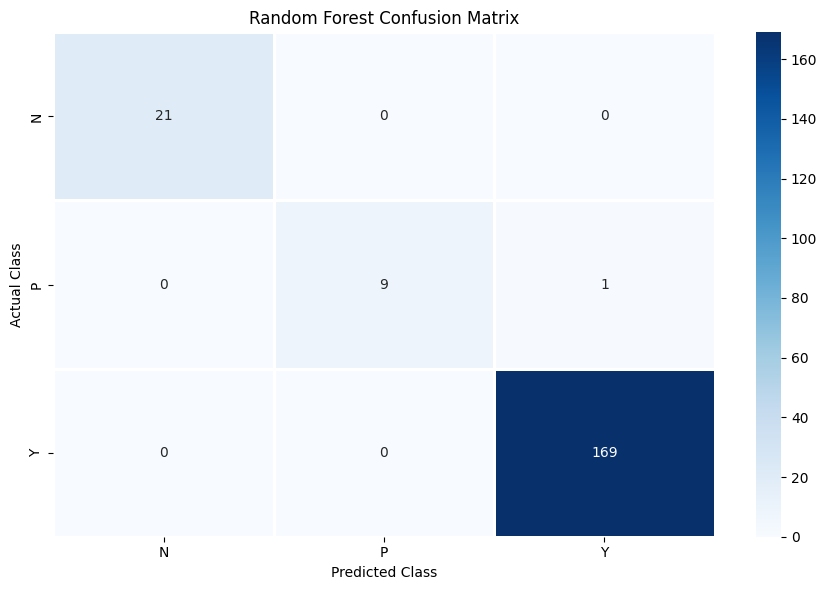

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['N', 'P', 'Y'])

# Create visualization
plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    xticklabels=['N', 'P', 'Y'],
    yticklabels=['N', 'P', 'Y']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()

# Save graph
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')

plt.show()

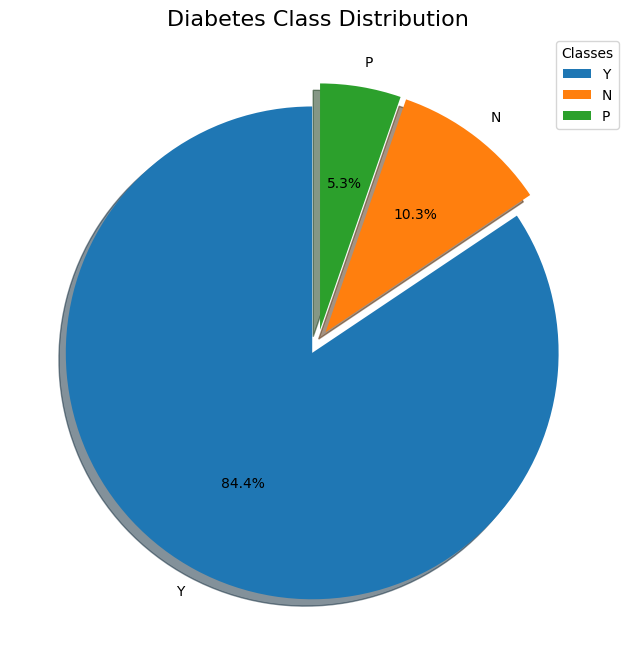

In [15]:
import matplotlib.pyplot as plt

# Count each diabetes class
class_counts = df['CLASS'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.05] * len(class_counts),
    shadow=True
)

plt.title('Diabetes Class Distribution', fontsize=16)
plt.legend(
    labels=class_counts.index,
    title='Classes',
    loc='best'
)

plt.savefig(
    'diabetes_class_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

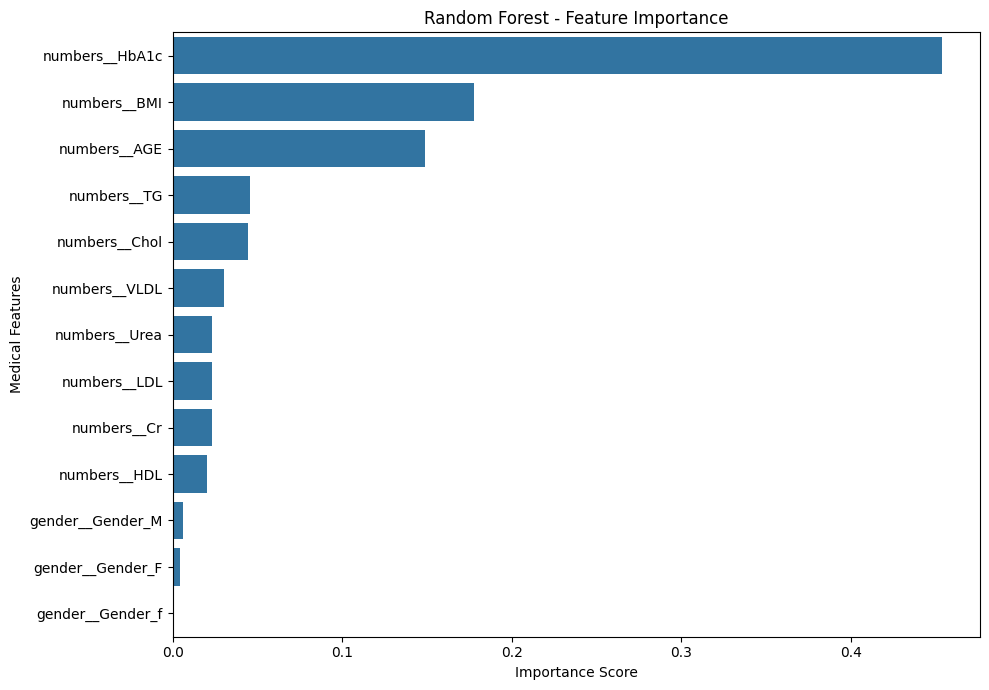

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract trained Random Forest model
rf_model = model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = model.named_steps['preprocessing'].get_feature_names_out()

# Get feature importance values
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Plot graph
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Medical Features')
plt.tight_layout()

plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

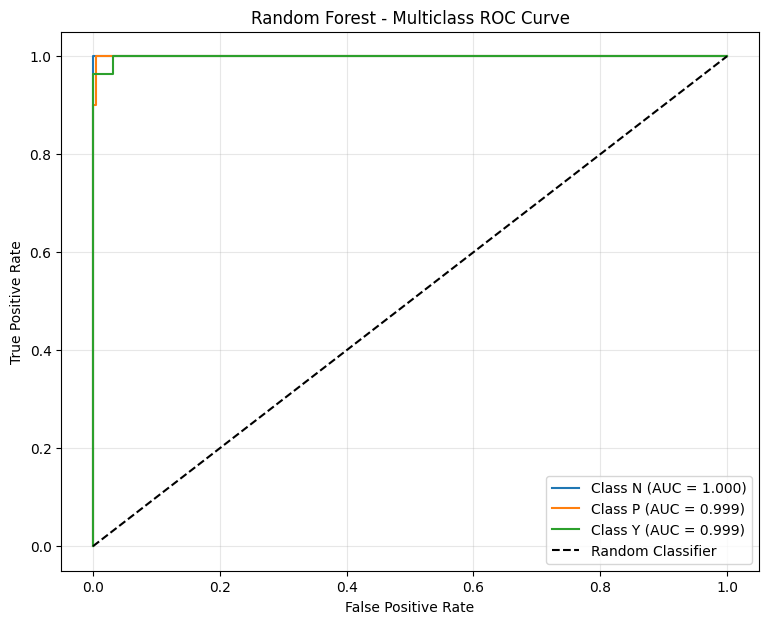

In [17]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Convert actual labels into binary format
classes = ['N', 'P', 'Y']

y_test_binary = label_binarize(y_test, classes=classes)

# Get prediction probabilities
y_prob = model.predict_proba(X_test)

# Plot ROC curves
plt.figure(figsize=(9, 7))

for i, class_name in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'Class {class_name} (AUC = {roc_auc:.3f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest - Multiclass ROC Curve')
plt.legend()
plt.grid(alpha=0.3)

plt.savefig('roc_auc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

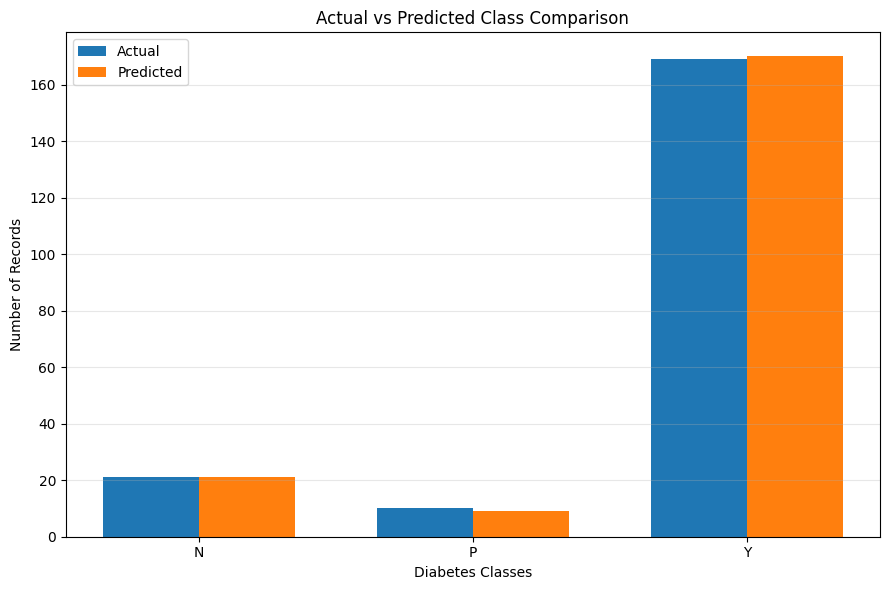

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Compare actual and predicted classes
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

# Count class occurrences
actual_counts = comparison['Actual'].value_counts().reindex(
    ['N', 'P', 'Y'], fill_value=0
)

predicted_counts = comparison['Predicted'].value_counts().reindex(
    ['N', 'P', 'Y'], fill_value=0
)

# Create comparison chart
labels = ['N', 'P', 'Y']
x = range(len(labels))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    [i - width/2 for i in x],
    actual_counts,
    width,
    label='Actual'
)

plt.bar(
    [i + width/2 for i in x],
    predicted_counts,
    width,
    label='Predicted'
)

plt.xlabel('Diabetes Classes')
plt.ylabel('Number of Records')
plt.title('Actual vs Predicted Class Comparison')
plt.xticks(list(x), labels)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=300)
plt.show()

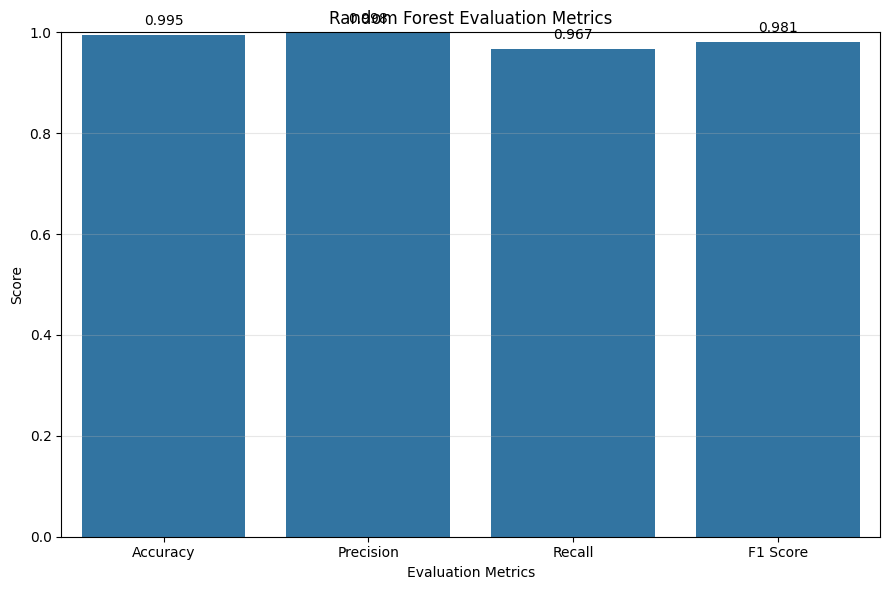

,Metric,Score
0,Accuracy,0.995000
1,Precision,0.998039
2,Recall,0.966667
3,F1 Score,0.981473


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate evaluation metrics
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(
        y_test, y_pred, average='macro', zero_division=0
    ),
    'Recall': recall_score(
        y_test, y_pred, average='macro', zero_division=0
    ),
    'F1 Score': f1_score(
        y_test, y_pred, average='macro', zero_division=0
    )
}

# Create DataFrame
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=['Metric', 'Score']
)

# Plot evaluation graph
plt.figure(figsize=(9, 6))

sns.barplot(
    data=metrics_df,
    x='Metric',
    y='Score'
)

plt.title('Random Forest Evaluation Metrics')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(metrics_df['Score']):
    plt.text(i, value + 0.02, f'{value:.3f}', ha='center')

plt.tight_layout()
plt.savefig('evaluation_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

display(metrics_df)

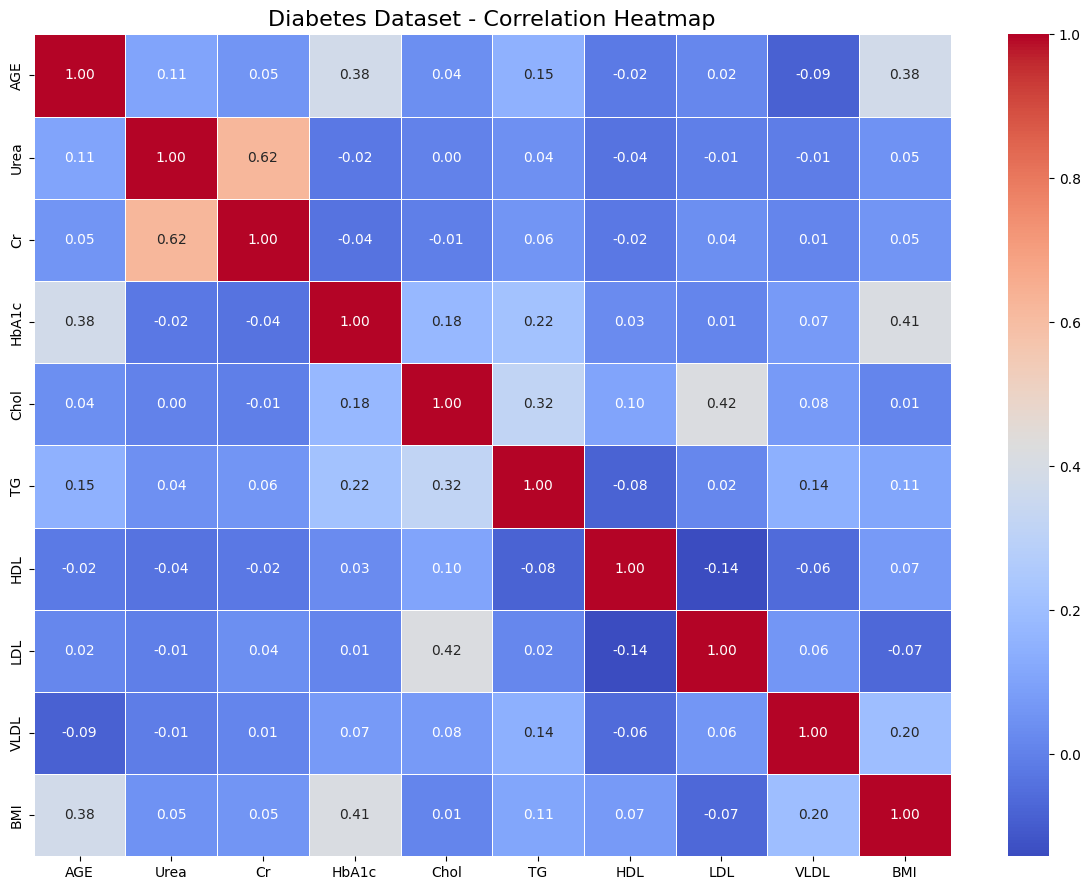

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_df = df.select_dtypes(include=['number'])

# Calculate correlation
correlation = numerical_df.corr()

# Create heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Diabetes Dataset - Correlation Heatmap', fontsize=16)
plt.tight_layout()

plt.savefig(
    'correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()